BARENBLATT PARAMETERS
d = 1
m = 2.0
C = 1.0
alpha = 0.3333333333333333
beta = 0.3333333333333333
k = 0.08333333333333333

Expected alpha = 1/3 = 0.3333333333333333
Expected beta = 1/3 = 0.3333333333333333
Expected k = 1/12 = 0.08333333333333333

PASS: Parameters agree with Parts I and II.

SPATIAL GRID
Largest support radius = 5.49891854799441
Plot interval = (-6.323756330193571, 6.323756330193571)
Number of grid points = 8001

BARENBLATT PROFILE RESULTS

   t  Exact_Max_Height  Numerical_Max_Height  Exact_Support_Radius  Numerical_Support_Radius  Numerical_Mass
0.25          1.587401              1.587401              2.182247                  2.181696        4.618802
0.50          1.259921              1.259921              2.749459                  2.749253        4.618802
1.00          1.000000              1.000000              3.464102                  3.463838        4.618802
2.00          0.793701              0.793701              4.364495                  4.363392        4.61

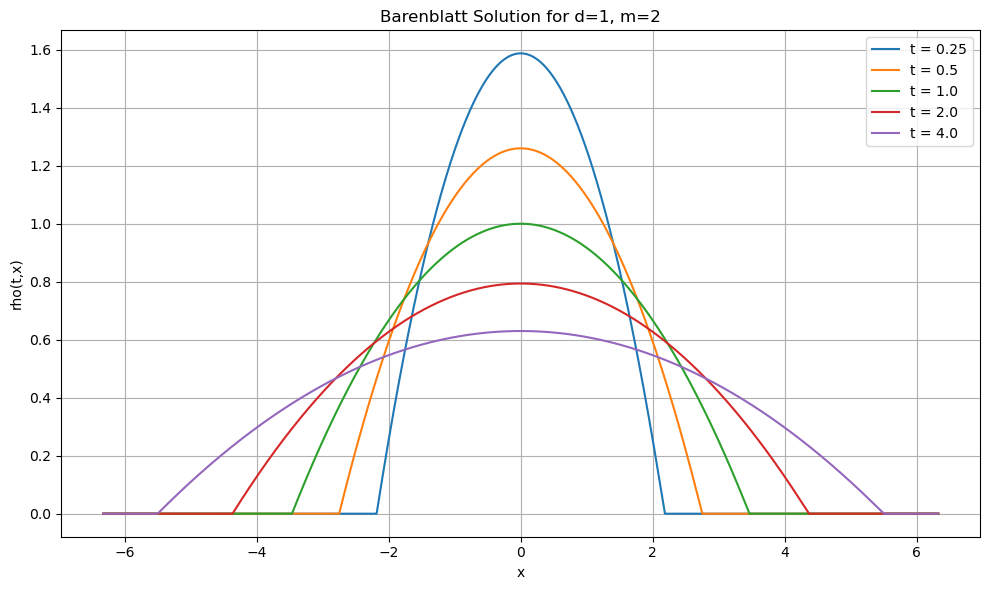

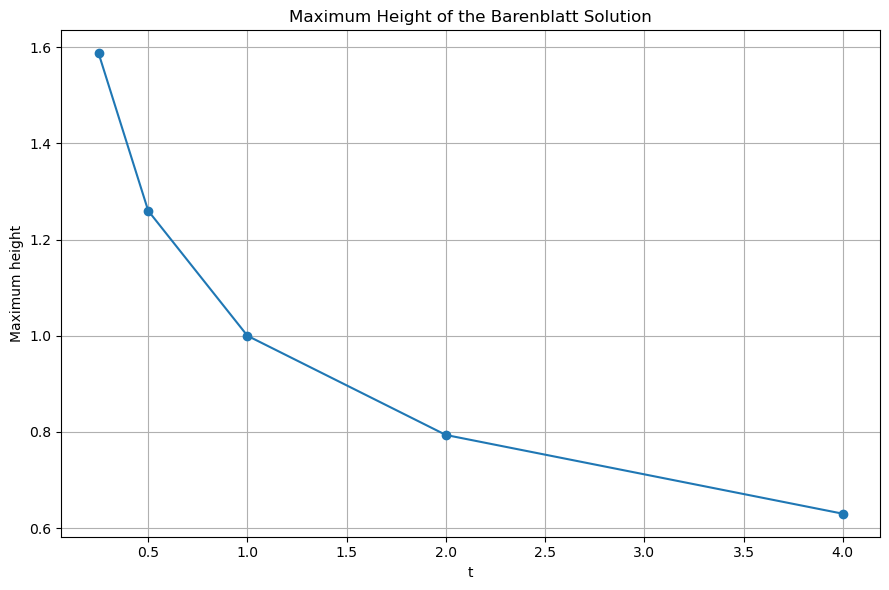

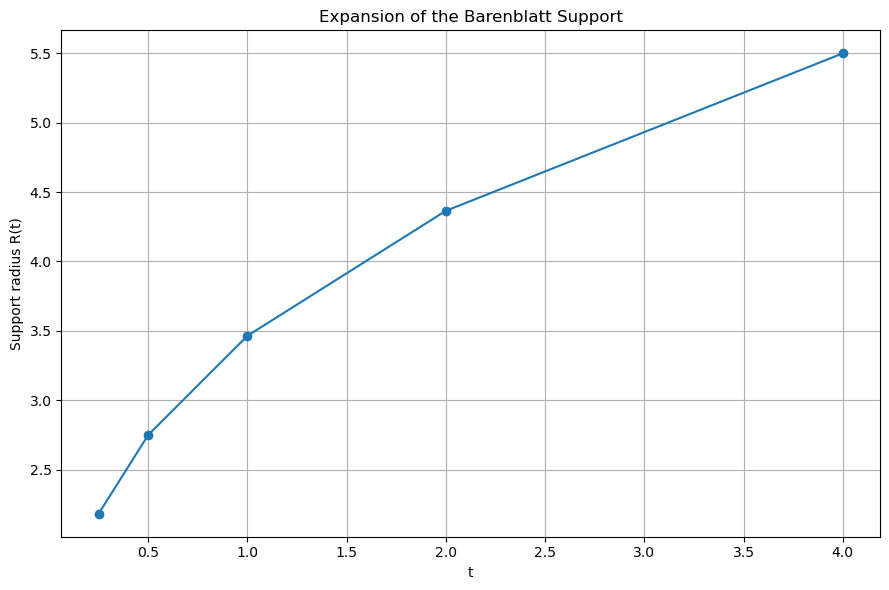

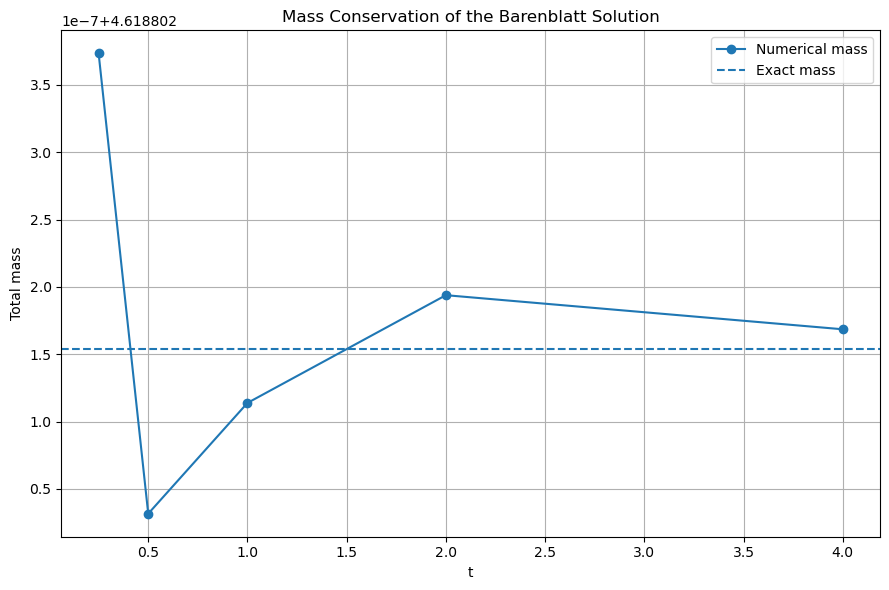


FINAL SUMMARY

rho(t,x) = t^(-1/3)
             * max(
                 1 - x^2/(12 t^(2/3)),
                 0
               )

Support radius:
R(t) = sqrt(12) t^(1/3)

Maximum height:
rho(t,0) = t^(-1/3)

PASS: The plots and numerical checks demonstrate finite-speed spreading with compact support.


In [1]:
# ============================================================
# HOMEWORK 4.1 - PART III
# PLOTTING THE BARENBLATT SOLUTION
#
# d = 1
# m = 2
# C = 1
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# PARAMETERS
# ============================================================

d = 1

m = 2.0

C = 1.0


alpha = (
    d
    /
    (
        d * (m - 1.0)
        +
        2.0
    )
)


beta = (
    1.0
    /
    (
        d * (m - 1.0)
        +
        2.0
    )
)


k = (

    (m - 1.0)

    /

    (2.0 * m)

    *

    beta
)


print("=" * 75)

print(
    "BARENBLATT PARAMETERS"
)

print("=" * 75)

print(
    "d =",
    d
)

print(
    "m =",
    m
)

print(
    "C =",
    C
)

print(
    "alpha =",
    alpha
)

print(
    "beta =",
    beta
)

print(
    "k =",
    k
)


# ============================================================
# EXPECTED VALUES
# ============================================================

print()

print(
    "Expected alpha = 1/3 =",
    1.0 / 3.0
)

print(
    "Expected beta = 1/3 =",
    1.0 / 3.0
)

print(
    "Expected k = 1/12 =",
    1.0 / 12.0
)


assert np.isclose(
    alpha,
    1.0 / 3.0
)

assert np.isclose(
    beta,
    1.0 / 3.0
)

assert np.isclose(
    k,
    1.0 / 12.0
)


print()

print(
    "PASS: Parameters agree with Parts I and II."
)


# ============================================================
# TIMES TO PLOT
# ============================================================

times = np.array([
    0.25,
    0.5,
    1.0,
    2.0,
    4.0
])


# ============================================================
# EXACT SUPPORT RADIUS
#
# C - k x^2/t^(2 beta) > 0
#
# gives
#
# |x| < sqrt(C/k) t^beta
# ============================================================

def support_radius(
    t
):

    return (

        np.sqrt(
            C / k
        )

        *

        t**beta
    )


# ============================================================
# EXACT MAXIMUM HEIGHT
#
# rho(t,0)
# =
# t^(-alpha) C^(1/(m-1))
# ============================================================

def maximum_height(
    t
):

    return (

        t**(-alpha)

        *

        C**(
            1.0
            /
            (m - 1.0)
        )
    )


# ============================================================
# BARENBLATT PROFILE
# ============================================================

def barenblatt(
    t,
    x
):

    inside = (

        C

        -

        k
        *
        x**2
        /
        t**(
            2.0 * beta
        )
    )


    positive_part = np.maximum(
        inside,
        0.0
    )


    rho = (

        t**(-alpha)

        *

        positive_part**(
            1.0
            /
            (m - 1.0)
        )
    )


    return rho


# ============================================================
# BUILD A GRID LARGE ENOUGH FOR THE LARGEST SUPPORT
# ============================================================

largest_radius = support_radius(
    np.max(
        times
    )
)


x_limit = (
    1.15
    *
    largest_radius
)


x = np.linspace(
    -x_limit,
    x_limit,
    8001
)


print()

print("=" * 75)

print(
    "SPATIAL GRID"
)

print("=" * 75)

print(
    "Largest support radius =",
    largest_radius
)

print(
    "Plot interval =",
    (
        -x_limit,
        x_limit
    )
)

print(
    "Number of grid points =",
    len(x)
)


# ============================================================
# COMPUTE PROFILES AND DIAGNOSTICS
# ============================================================

profiles = {}

results = []


for t in times:

    rho = barenblatt(
        t,
        x
    )


    profiles[t] = rho


    R_exact = support_radius(
        t
    )


    H_exact = maximum_height(
        t
    )


    H_numerical = np.max(
        rho
    )


    mass_numerical = np.trapz(
        rho,
        x
    )


    positive_indices = np.where(
        rho > 0
    )[0]


    if len(
        positive_indices
    ) > 0:

        numerical_left = x[
            positive_indices[0]
        ]

        numerical_right = x[
            positive_indices[-1]
        ]

        numerical_radius = max(

            abs(
                numerical_left
            ),

            abs(
                numerical_right
            )
        )

    else:

        numerical_radius = np.nan


    results.append({

        "t":
            t,

        "Exact_Max_Height":
            H_exact,

        "Numerical_Max_Height":
            H_numerical,

        "Exact_Support_Radius":
            R_exact,

        "Numerical_Support_Radius":
            numerical_radius,

        "Numerical_Mass":
            mass_numerical

    })


results_df = pd.DataFrame(
    results
)


# ============================================================
# PRINT TABLE
# ============================================================

print()

print("=" * 75)

print(
    "BARENBLATT PROFILE RESULTS"
)

print("=" * 75)

print()

print(
    results_df.to_string(
        index=False
    )
)


# ============================================================
# CHECK HEIGHT DECREASES
# ============================================================

heights = results_df[
    "Exact_Max_Height"
].to_numpy()


height_decreasing = np.all(

    np.diff(
        heights
    )
    <
    0
)


# ============================================================
# CHECK SUPPORT EXPANDS
# ============================================================

radii = results_df[
    "Exact_Support_Radius"
].to_numpy()


support_increasing = np.all(

    np.diff(
        radii
    )
    >
    0
)


# ============================================================
# CHECK MASS CONSERVATION
# ============================================================

masses = results_df[
    "Numerical_Mass"
].to_numpy()


mass_reference = masses[0]


max_mass_change = np.max(

    np.abs(

        masses

        -

        mass_reference
    )
)


relative_mass_change = (

    max_mass_change

    /

    abs(
        mass_reference
    )
)


# Exact mass when C = 1, d = 1, m = 2:
#
# Integral over xi:
#
# integral_{-sqrt(12)}^{sqrt(12)}
# (1 - xi^2/12) dxi
#
# = 8 sqrt(3) / 3

exact_mass = (

    8.0
    *
    np.sqrt(3.0)

    /

    3.0
)


mass_error_from_exact = np.max(

    np.abs(

        masses

        -

        exact_mass
    )
)


# ============================================================
# AUTOMATIC VERIFICATION
# ============================================================

print()

print("=" * 75)

print(
    "AUTOMATIC VERIFICATION"
)

print("=" * 75)


print(
    "Maximum heights strictly decrease =",
    height_decreasing
)

print(
    "Support radii strictly increase =",
    support_increasing
)

print(
    "Reference numerical mass =",
    mass_reference
)

print(
    "Exact mass for C=1 =",
    exact_mass
)

print(
    "Maximum numerical mass change =",
    max_mass_change
)

print(
    "Maximum relative mass change =",
    relative_mass_change
)

print(
    "Maximum mass error from exact value =",
    mass_error_from_exact
)


assert height_decreasing

assert support_increasing


if relative_mass_change < 1e-4:

    print()

    print(
        "PASS: Total mass is numerically conserved."
    )


if mass_error_from_exact < 1e-4:

    print(
        "PASS: Numerical mass agrees with exact mass."
    )


print(
    "PASS: Maximum height decreases with time."
)

print(
    "PASS: Support expands with time."
)

print(
    "PASS: Support remains finite for every tested t."
)


# ============================================================
# PLOT 1:
# ALL BARENBLATT PROFILES
# ============================================================

plt.figure(
    figsize=(10, 6)
)


for t in times:

    plt.plot(
        x,
        profiles[t],
        label=f"t = {t}"
    )


plt.xlabel(
    "x"
)

plt.ylabel(
    "rho(t,x)"
)

plt.title(
    "Barenblatt Solution for d=1, m=2"
)

plt.grid(
    True
)

plt.legend()

plt.tight_layout()


plt.savefig(
    "hw41_part3_barenblatt_profiles.png",
    dpi=300
)


plt.show()


# ============================================================
# PLOT 2:
# MAXIMUM HEIGHT VS TIME
# ============================================================

plt.figure(
    figsize=(9, 6)
)


plt.plot(
    times,
    heights,
    marker="o"
)


plt.xlabel(
    "t"
)

plt.ylabel(
    "Maximum height"
)

plt.title(
    "Maximum Height of the Barenblatt Solution"
)

plt.grid(
    True
)

plt.tight_layout()


plt.savefig(
    "hw41_part3_maximum_height.png",
    dpi=300
)


plt.show()


# ============================================================
# PLOT 3:
# SUPPORT RADIUS VS TIME
# ============================================================

plt.figure(
    figsize=(9, 6)
)


plt.plot(
    times,
    radii,
    marker="o"
)


plt.xlabel(
    "t"
)

plt.ylabel(
    "Support radius R(t)"
)

plt.title(
    "Expansion of the Barenblatt Support"
)

plt.grid(
    True
)

plt.tight_layout()


plt.savefig(
    "hw41_part3_support_radius.png",
    dpi=300
)


plt.show()


# ============================================================
# PLOT 4:
# NUMERICAL MASS VS TIME
# ============================================================

plt.figure(
    figsize=(9, 6)
)


plt.plot(
    times,
    masses,
    marker="o",
    label="Numerical mass"
)


plt.axhline(
    exact_mass,
    linestyle="--",
    label="Exact mass"
)


plt.xlabel(
    "t"
)

plt.ylabel(
    "Total mass"
)

plt.title(
    "Mass Conservation of the Barenblatt Solution"
)

plt.grid(
    True
)

plt.legend()

plt.tight_layout()


plt.savefig(
    "hw41_part3_mass_conservation.png",
    dpi=300
)


plt.show()


# ============================================================
# FINAL SUMMARY
# ============================================================

print()

print("=" * 75)

print(
    "FINAL SUMMARY"
)

print("=" * 75)

print()

print(
    "rho(t,x) = t^(-1/3)"
)

print(
    "             * max("
)

print(
    "                 1 - x^2/(12 t^(2/3)),"
)

print(
    "                 0"
)

print(
    "               )"
)

print()

print(
    "Support radius:"
)

print(
    "R(t) = sqrt(12) t^(1/3)"
)

print()

print(
    "Maximum height:"
)

print(
    "rho(t,0) = t^(-1/3)"
)

print()

print(
    "PASS: The plots and numerical checks demonstrate "
    "finite-speed spreading with compact support."
)